In [423]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import xgboost as xgb
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix

In [424]:
df=pd.read_csv('Merge_data_v5_selected.csv')

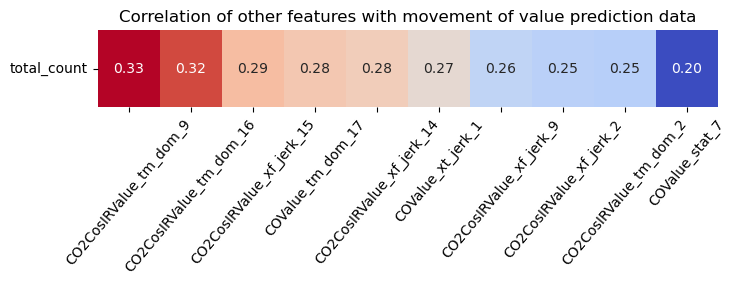

In [428]:
import seaborn as sns
import matplotlib.pyplot as plt

# Your code to generate top_correlation_matrix

# Extract only the last row (which corresponds to 'total_count')
total_count_corr = top_correlation_matrix.iloc[-1:]

# Create a heatmap for the last row
plt.figure(figsize=(8, 1))  # Adjust the figure size as needed
heatmap = sns.heatmap(total_count_corr, annot=True, cmap='coolwarm', fmt=".2f", cbar=False)

plt.title("Correlation of other features with movement of value prediction data")
plt.xticks(rotation=50)  # Rotate x-axis labels if needed
plt.yticks(rotation=0)   # Rotate y-axis labels if needed
plt.show()

In [34]:
df['move_type'] = df['total_count'].apply(lambda x: 0 if x == 0 else 1 if 1 <= x <= 4 else 2)

In [422]:
df['move_type'].value_counts()

2    958
1    530
0    450
Name: move_type, dtype: int64

In [425]:
del df['Unnamed: 0']

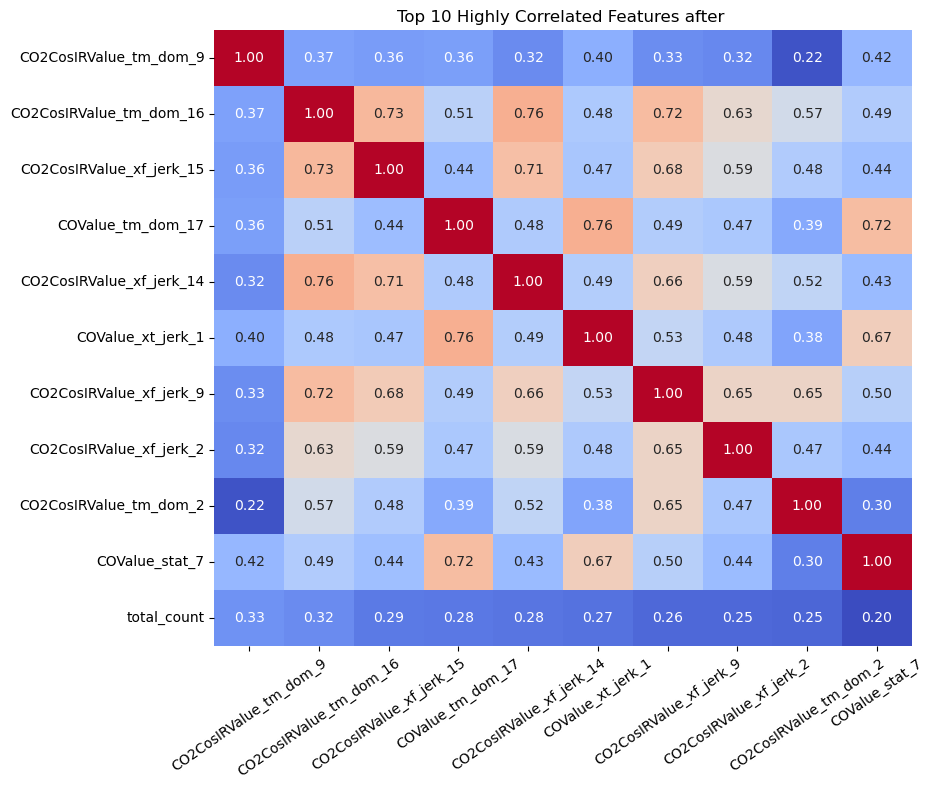

In [426]:
correlation_matrix = df.corr()
top_correlated_features = correlation_matrix['total_count'].sort_values(ascending=False)[1:11]

# Get the top correlated features names
top_correlated_features_names = top_correlated_features.index.tolist()

# Include 'total_count' in the list of top correlated features
top_correlated_features_names.append('total_count')

# Extract the correlation values for these features
top_correlation_matrix = df[top_correlated_features_names].corr()

# Drop duplicate 'total_count' column if it exists
if 'total_count' in top_correlation_matrix.columns:
    top_correlation_matrix.drop(columns=['total_count'], inplace=True)
# Create a heatmap
plt.figure(figsize=(9, 8))
heatmap=sns.heatmap(top_correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f", cbar=False)
heatmap.set_xticklabels(heatmap.get_xticklabels(), rotation=35)

plt.title("Top 10 Features of value prediction proceseed data ")
plt.show()

In [37]:
drop_features = ['total_count','move_type']
target_feature = 'move_type'

In [38]:
X = df.drop(drop_features, axis=1)
y = df[target_feature]

In [39]:
X

,CO2CosIRValue_tm_dom_9,CO2CosIRValue_xf_jerk_9,CO2CosIRValue_tm_dom_2,CO2CosIRValue_tm_dom_16,CO2CosIRValue_xf_jerk_2,CO2CosIRValue_xf_jerk_14,CO2CosIRValue_xf_jerk_15,COValue_stat_7,COValue_xt_jerk_1,COValue_tm_dom_17
0,1.182329e+08,77540.839509,1.164276,120.839121,3.013913,9.326055,17.929601,1.260655,10.506700,82.449622
1,1.106247e+08,42434.593364,0.283703,114.836023,4.096936,13.772698,14.457048,4.673625,8.142400,198.747468
2,1.210164e+08,23413.255832,1.790157,53.435480,0.658388,2.720878,4.244554,1.712750,7.990829,106.576297
3,1.243438e+08,37747.290022,1.619635,66.845466,0.101616,3.876383,1.374782,0.992575,5.621770,75.397925
4,1.850559e+08,13561.770508,1.768394,171.191384,0.844150,3.720942,3.582027,1.418210,9.395000,101.438317
...,...,...,...,...,...,...,...,...,...,...
1933,3.075874e+07,1394.124482,0.324107,33.442356,0.372326,4.276276,3.252815,0.762700,2.486390,21.970224
1934,3.020993e+07,1917.410045,0.254504,39.425697,0.253513,3.289474,2.198457,1.880970,4.433585,28.702458
1935,3.045677e+07,1327.619145,0.213863,47.763206,0.518474,4.845247,3.356308,1.334550,1.535650,28.442120
1936,3.096077e+07,1837.842588,0.642697,24.268284,0.164744,2.345866,1.234827,0.583330,3.174860,35.612119


In [40]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.25,random_state=877)

In [41]:
from sklearn.metrics import classification_report

# Logistic classifier

In [194]:
model1 = LogisticRegression(max_iter=1000,multi_class='ovr', random_state=122,C=10,penalty='l2',solver='newton-cg')
model1.fit(X_train,y_train)
y_pred=model1.predict(X_test)

/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:457: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:306: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:416: LineSearchWarning: Rounding errors prevent the line search from converging
  warn(msg, LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/utils/optimize.py:203: UserWarning: Line Search failed
  warnings.warn("Line Search failed")


In [195]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.69
Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.86      0.83       112
           1       0.00      0.00      0.00       113
           2       0.66      0.92      0.77       260

    accuracy                           0.69       485
   macro avg       0.49      0.59      0.53       485
weighted avg       0.54      0.69      0.60       485



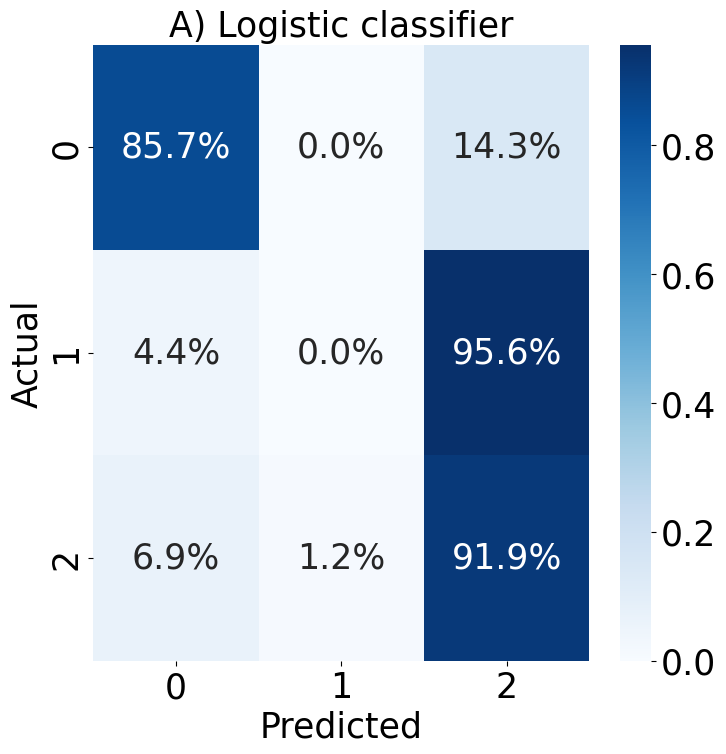

In [196]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('A) Logistic classifier',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
#cbar.set_ticks(np.linspace(0, .81, num=9))  # Set custom tick locations
#cbar.set_ticklabels(['0.0', '0.1', '0.2', '0.3', '0.4', '0.5', '0.6', '0.7', '0.8']) 
plt.show()

# Decision Tree

In [197]:
model2 = DecisionTreeClassifier(max_depth=3,criterion='entropy',min_samples_split=2,min_samples_leaf=1,splitter='best')
model2.fit(X_train,y_train)
y_pred=model2.predict(X_test)

In [198]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)

print(f"Accuracy: {accuracy:.2f}")
print("Classification Report:\n", report)

Accuracy: 0.69
Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.79      0.83       112
           1       0.39      0.11      0.17       113
           2       0.66      0.90      0.76       260

    accuracy                           0.69       485
   macro avg       0.64      0.60      0.59       485
weighted avg       0.65      0.69      0.64       485



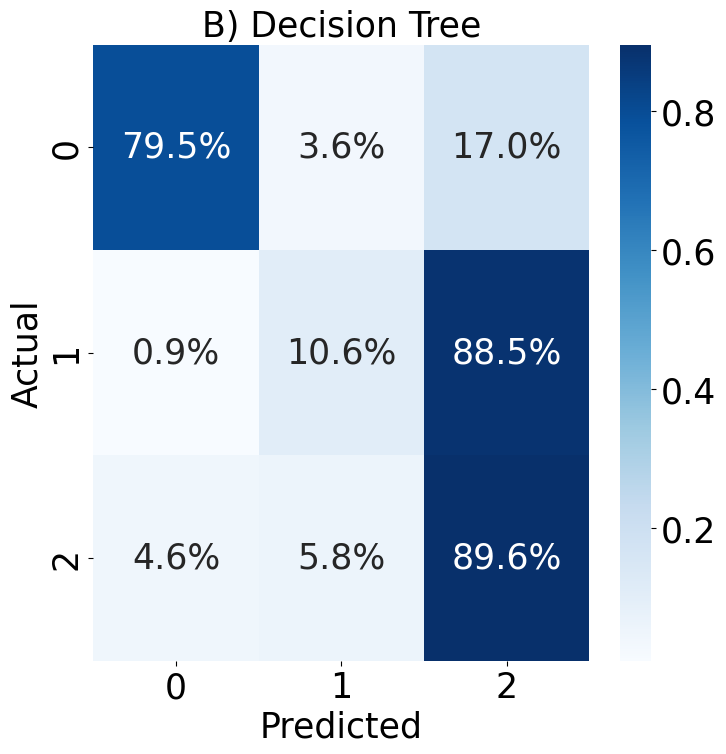

In [199]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('B) Decision Tree',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

# Random Forest

In [407]:
model3 = RandomForestClassifier(n_estimators=250,max_depth=5)
model3.fit(X_train, y_train)

# Make predictions
y_pred = model3.predict(X_test)

# Evaluate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy}')
report = classification_report(y_test, y_pred)
print("Classification Report:\n", report)

Accuracy: 0.7484536082474227
Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.83      0.88       112
           1       0.67      0.25      0.36       113
           2       0.71      0.93      0.80       260

    accuracy                           0.75       485
   macro avg       0.77      0.67      0.68       485
weighted avg       0.75      0.75      0.72       485



In [408]:
y_pred_train = model3.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print(f'Accuracy: {accuracy}')

Accuracy: 0.735719201651755


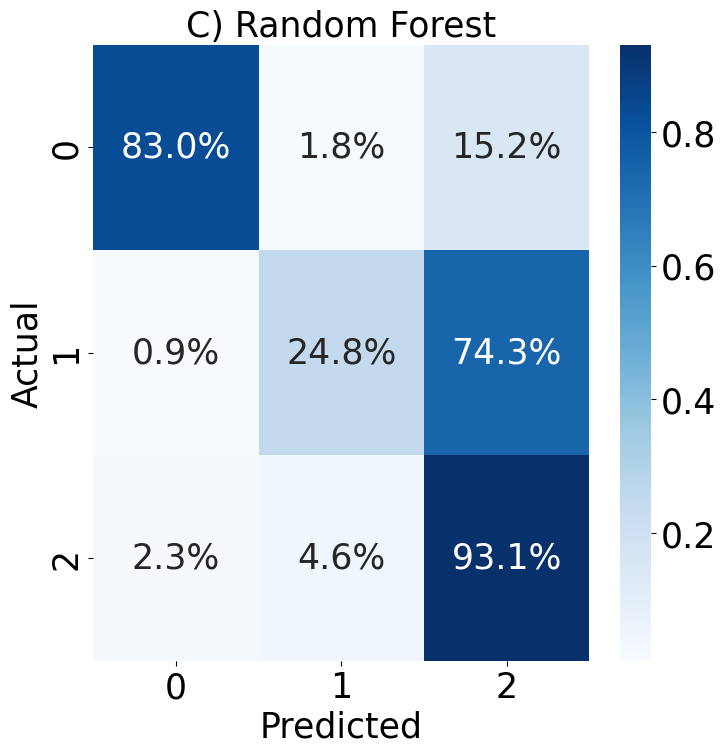

In [409]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('C) Random Forest',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

# XGboost

In [410]:
model4=xgb.XGBClassifier(objective='multi:softmax',colsample_bytree=0.8,learning_rate=0.0001,max_depth=3,n_estimators=150,subsample=0.7, num_class=len(set(y)))
model4.fit(X_train,y_train)
y_pred=model4.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")
print("Classification Report:\n", report)

Accuracy: 0.753
Classification Report:
               precision    recall  f1-score   support

           0       0.92      0.84      0.88       112
           1       0.65      0.28      0.40       113
           2       0.72      0.92      0.80       260

    accuracy                           0.75       485
   macro avg       0.76      0.68      0.69       485
weighted avg       0.75      0.75      0.73       485



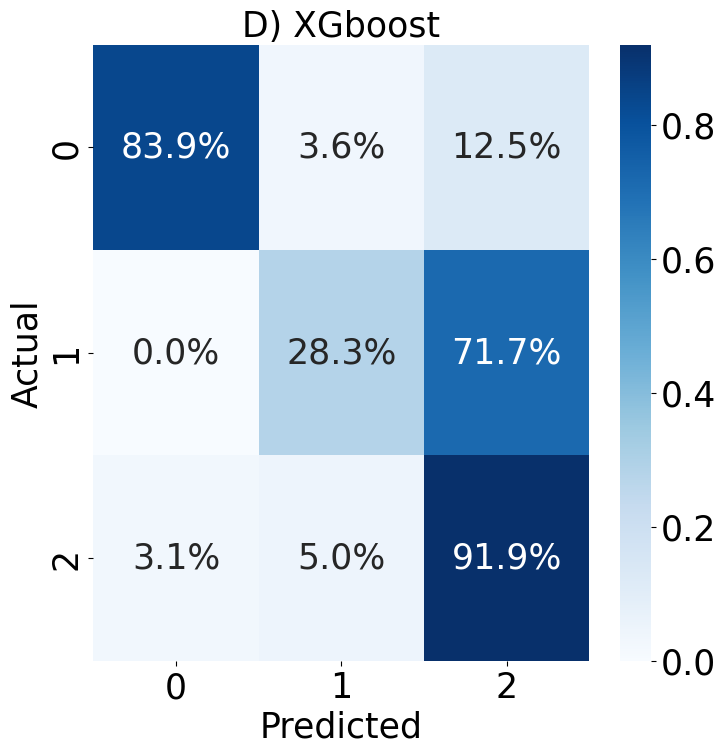

In [411]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('D) XGboost',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

# Naive bayes

In [412]:
# Initialize Gaussian Naive Bayes classifier
model5 = GaussianNB()

# Train the classifier
model5.fit(X_train, y_train)

# Predictions
y_pred = model5.predict(X_test)

# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print("Accuracy:", accuracy)
print("Classification Report:\n", report)

Accuracy: 0.422680412371134
Classification Report:
               precision    recall  f1-score   support

           0       0.53      0.89      0.66       112
           1       0.30      0.67      0.42       113
           2       0.64      0.11      0.19       260

    accuracy                           0.42       485
   macro avg       0.49      0.56      0.42       485
weighted avg       0.54      0.42      0.35       485



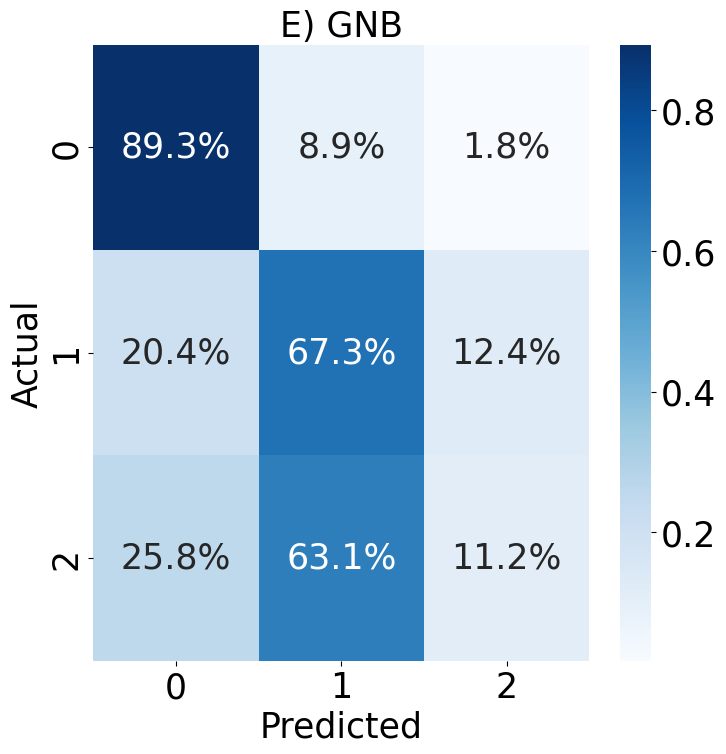

In [413]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('E) GNB',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

# Ensemble

In [414]:
from sklearn.ensemble import VotingClassifier

In [415]:
voting_clf = VotingClassifier(
    estimators=[('lr', model1), ('df', model2), ('rf', model3),('xgb', model4),('gnb', model5)],
    voting='hard'  # other options: 'soft' for soft voting
)

# Train the voting classifier
voting_clf.fit(X_train, y_train)

# Make predictions
y_pred = voting_clf.predict(X_test)

/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:457: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:306: LineSearchWarning: The line search algorithm did not converge
  warn('The line search algorithm did not converge', LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/scipy/optimize/_linesearch.py:416: LineSearchWarning: Rounding errors prevent the line search from converging
  warn(msg, LineSearchWarning)
/Users/sayemahmed/anaconda3/lib/python3.11/site-packages/sklearn/utils/optimize.py:203: UserWarning: Line Search failed
  warnings.warn("Line Search failed")


In [416]:
accuracy = accuracy_score(y_test, y_pred)
report = classification_report(y_test, y_pred)
print("Accuracy:", accuracy)
print("Classification Report:\n", report)

Accuracy: 0.7381443298969073
Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.86      0.86       112
           1       0.62      0.23      0.34       113
           2       0.71      0.91      0.80       260

    accuracy                           0.74       485
   macro avg       0.73      0.66      0.67       485
weighted avg       0.73      0.74      0.70       485



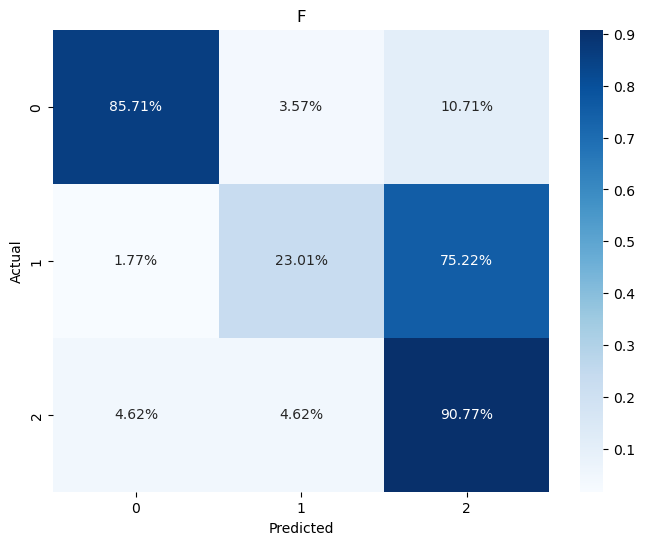

In [417]:
conf_matrix = confusion_matrix(y_test, y_pred)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix_percentage, annot=True, fmt='.2%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('F')
plt.show()

In [421]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score

lr_pred = model1.predict(X_test)
df_pred = model2.predict(X_test)
rf_pred = model3.predict(X_test)
xgb_pred = model4.predict(X_test)
gnb_pred = model5.predict(X_test)

X_pred = np.column_stack((lr_pred, df_pred, rf_pred, xgb_pred, gnb_pred))

decision_tree_final = DecisionTreeClassifier(max_depth=7)
decision_tree_final.fit(X_pred, y_test)

final_prediction = decision_tree_final.predict(X_pred)

final_accuracy = accuracy_score(y_test, final_prediction)
print("Accuracy:", final_accuracy)

Accuracy: 0.7731958762886598


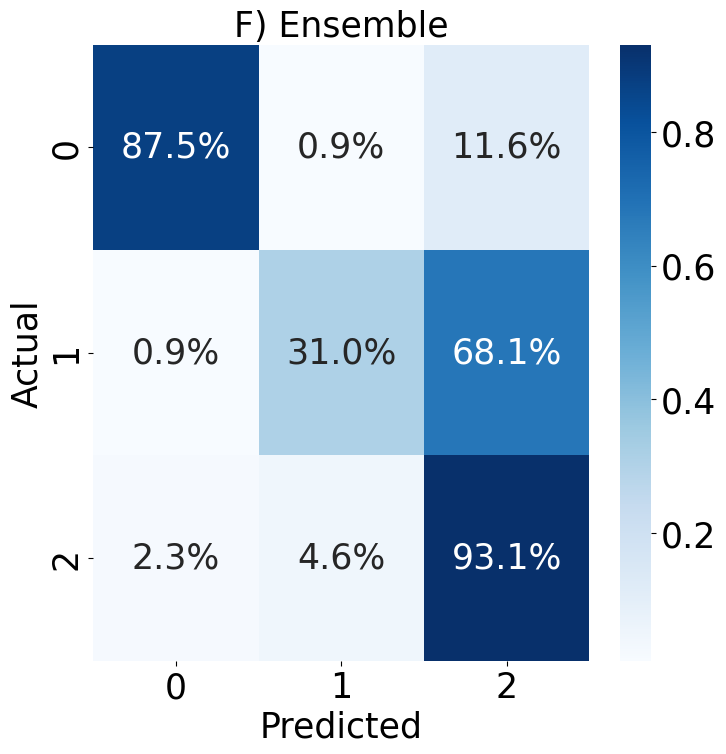

In [420]:
conf_matrix = confusion_matrix(y_test, final_prediction)
conf_matrix_percentage = conf_matrix.astype('float') / conf_matrix.sum(axis=1)[:, np.newaxis]  # Calculate percentages

plt.figure(figsize=(8, 8))
heatmap=sns.heatmap(conf_matrix_percentage, annot=True, fmt='.1%', cmap='Blues', xticklabels=[0,1,2], yticklabels=[0,1,2],annot_kws={"size": 25})
plt.xticks(fontsize=25)
plt.yticks(fontsize=25)
plt.xlabel('Predicted',fontsize=25)
plt.ylabel('Actual',fontsize=25)
plt.title('F) Ensemble',fontsize=25)
cbar = heatmap.collections[0].colorbar
cbar.ax.tick_params(labelsize=25)
plt.show()

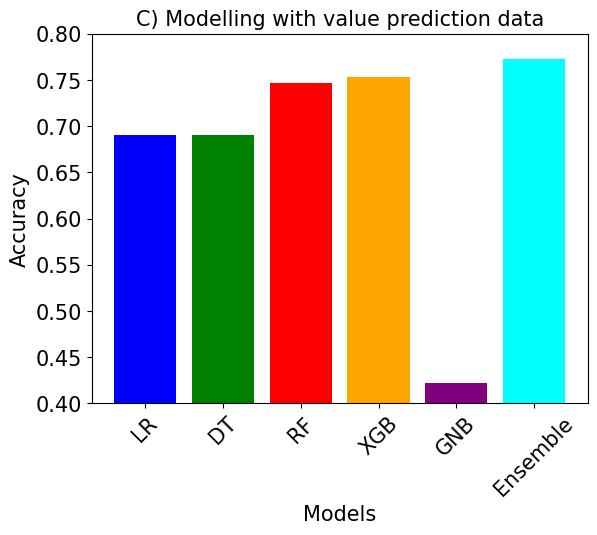

In [430]:
import matplotlib.pyplot as plt

# Sample data
categories = ['LR', 'DT', 'RF', 'XGB','GNB','Ensemble']
values = [0.69, 0.69, 0.7463, 0.753,0.422,0.7731]
colors = ['blue', 'green', 'red', 'orange', 'purple', 'cyan']

# Create bar plot
plt.bar(categories, values, color=colors)

# Adding title and labels
plt.title('C) Modelling with value prediction data',fontsize=15)
plt.xlabel('Models',fontsize=15)
plt.ylabel('Accuracy',fontsize=15)
plt.xticks(rotation=45, fontsize=15)
plt.yticks(fontsize=15)
plt.ylim(0.4, 0.8)
# Display the plot
plt.show()